# M2 — baseline scenario generator

3-factor PCA, VAR(1) on daily factor changes, independent Student-t shocks, zero drift, factors-only curve reconstruction. Decisions are in `LOG.md`. Validation against 2019-2026 belongs to M4 and lives elsewhere.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scenario_lab.data import load_curve
from scenario_lab import model as m
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"
levels = load_curve("AAA")
train = levels.loc[:m.FIT_END]
changes = train.diff().dropna()

## 1. Fit on the training window (2004-2018)

This is the M4 validation split. The fit prints the VAR(1) matrix `Phi`, the per-factor Student-t degrees of freedom `df` (floored at `MIN_DF`) and the residual std `sigma`.

In [2]:
p = m.fit(changes)
print("Phi:\n", p.Phi.round(3)); print("df:", p.df.round(2)); print("sigma:", p.sigma.round(5))

Phi:
 [[ 0.075 -0.009 -0.055]
 [-0.013  0.149 -0.182]
 [-0.013 -0.013  0.014]]
df: [5.24 3.04 3.  ]
sigma: [0.08047 0.0367  0.01921]


## 2. Simulate from the end of the training window

25,000 paths x 250 business days, starting from the last training curve. Output shape is `(paths, days + 1, maturities)`.

In [3]:
curves = m.simulate(p, train.iloc[-1].values)
curves.shape

(25000, 251, 6)

## 3. Theory check (VAR(1) closed form)

Simulated std of the factor state after 5 days vs the closed form, `Var = sum_k Phi^k Sigma Phi^k'`. Catches coding bugs (e.g. a transposed `Phi`). Expect agreement within a few percent; factor 3 sits on the `df` floor, so its std is noisier.

In [4]:
m.theory_check(p, curves)

,theory mean,sim_mean,theory std,sim_std
0,0.0,0.000151,0.080702,0.080948
1,0.0,0.000027,0.037300,0.036146
2,0.0,0.000014,0.019250,0.019428


## 4. Fan charts (training fit)

Grey: 50 sample paths. Blue band: 5-95% quantiles, line: median. Maturities 1Y, 10Y, 30Y.

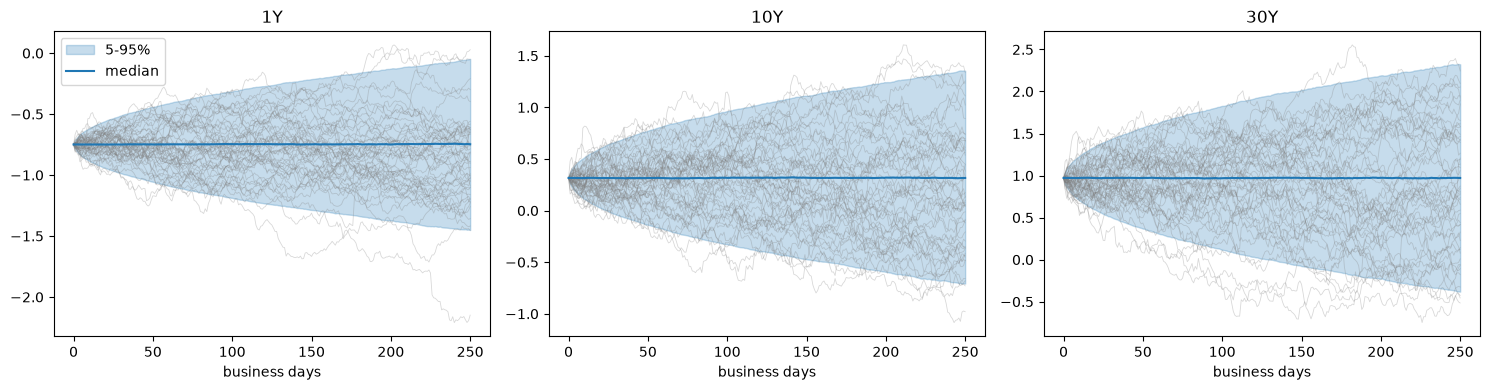

In [5]:
cols = [0, len(levels.columns) // 2, -1]
x = np.arange(curves.shape[1])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, j in zip(axes, cols):
    ax.plot(x, curves[:50, :, j].T, color="grey", alpha=0.3, lw=0.6)
    lo, med, hi = np.percentile(curves[:, :, j], [5, 50, 95], axis=0)
    ax.fill_between(x, lo, hi, color="C0", alpha=0.25, label="5-95%")
    ax.plot(x, med, color="C0", label="median")
    ax.set_title(f"{levels.columns[j]}"); ax.set_xlabel("business days")
axes[0].legend(); plt.tight_layout(); plt.show()

## 5. Production fit on all data (2004-2026)

Same model refit on the full sample. The table compares `sigma` and `df` with the training fit, to show how much 2019-2026 (including the 2022 hikes) moved the parameters.

In [6]:
changes_all = levels.diff().dropna()
p_all = m.fit(changes_all)
print("Phi:"); print(p_all.Phi.round(3)); print("df:", p_all.df.round(2)); print("sigma:", p_all.sigma.round(5))

Phi:
[[ 0.034 -0.008 -0.01 ]
 [-0.008  0.09  -0.137]
 [-0.007 -0.009 -0.029]]
df: [4.27 3.3  3.  ]
sigma: [0.08724 0.03773 0.01894]


In [7]:
sigma_comp = pd.DataFrame({"sigmas train": p.sigma.round(5), "sigma all": p_all.sigma.round(5)})
df_comp = pd.DataFrame({"df train": p.df.round(5), "df all": p_all.df.round(5)})
print(sigma_comp)
print(df_comp)

   sigmas train  sigma all
0       0.08047    0.08724
1       0.03670    0.03773
2       0.01921    0.01894
   df train   df all
0   5.24358  4.27482
1   3.04366  3.30174
2   3.00000  3.00000


## 6. Simulate from today

Start from the last observed curve; the first slice must equal it exactly.

In [8]:
y_now = levels.iloc[-1].values
curves_all = m.simulate(p_all, y_now)
print(curves_all.shape)
assert np.allclose(curves_all[:, 0], y_now)

(25000, 251, 6)


In [9]:
m.theory_check(p_all, curves_all)

,theory mean,sim_mean,theory std,sim_std
0,0.0,0.000392,0.087296,0.087216
1,0.0,-0.000054,0.037974,0.038061
2,0.0,-0.000015,0.018962,0.018012


## 7. Fan charts (production fit)

Realised levels for the last 500 days are shown to the left of day 0, so the starting point is visible.

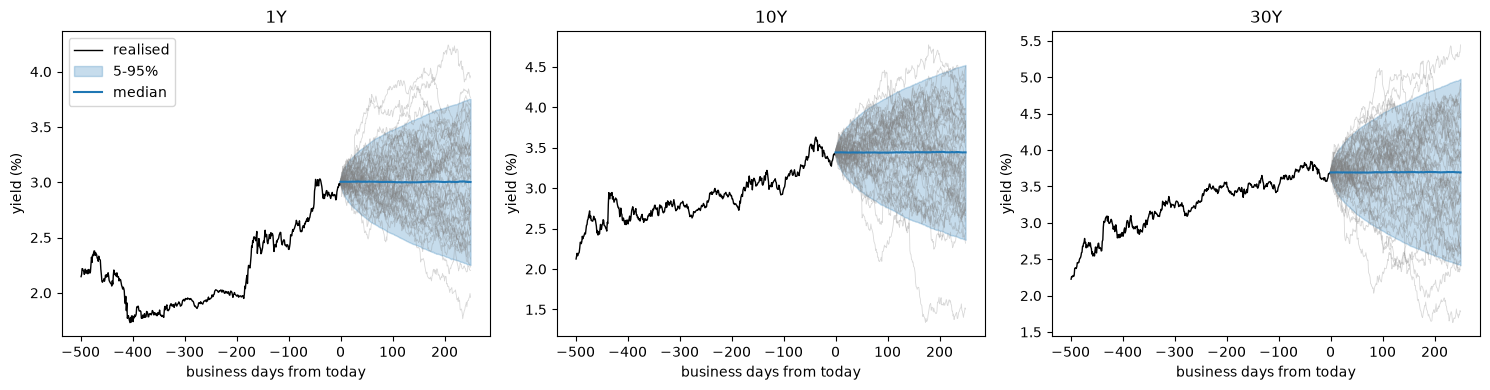

In [10]:
HIST = 500  # days of realised history shown left of day 0
x = np.arange(curves_all.shape[1])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, j in zip(axes, cols):
    ax.plot(-np.arange(HIST, 0, -1) + 1, levels.iloc[-HIST:, j].values, color="black", lw=1, label="realised")
    ax.plot(x, curves_all[:50, :, j].T, color="grey", alpha=0.3, lw=0.6)
    lo, med, hi = np.percentile(curves_all[:, :, j], [5, 50, 95], axis=0)
    ax.fill_between(x, lo, hi, color="C0", alpha=0.25, label="5-95%")
    ax.plot(x, med, color="C0", label="median")
    ax.set_title(f"{levels.columns[j]}"); ax.set_xlabel("business days from today"); ax.set_ylabel("yield (%)")
axes[0].legend(); plt.tight_layout(); plt.show()

## 8. Day-250 level quantiles

5/50/95% of the simulated yield after 250 business days, the starting level, and the fraction of paths below zero (levels are unbounded, so negative yields are possible).

In [11]:
q = pd.DataFrame(np.percentile(curves_all[:, -1], [5, 50, 95], axis=0).T,
                 index=levels.columns, columns=["5%", "50%", "95%"])
q["start"] = y_now
q["P(y<0)"] = (curves_all[:, -1] < 0).mean(axis=0)
q.round(3)

,5%,50%,95%,start,P(y<0)
1Y,2.252,3.002,3.752,3.004,0.0
2Y,2.098,3.125,4.144,3.125,0.0
5Y,2.119,3.190,4.262,3.188,0.0
10Y,2.361,3.443,4.522,3.442,0.0
20Y,2.570,3.732,4.899,3.729,0.0
30Y,2.417,3.692,4.977,3.692,0.0
